# PRCP-1001: Rice Leaf Disease Detection

**Objective:** Classify rice leaf images into three disease classes, and report on the data, the augmentation techniques, the model comparison and the challenges.

**Author:** ANJALY JINS
**Date:** 04-11-2026

## 0. Environment setup (done in the Anaconda Prompt, before this notebook)

These steps run in a terminal and cannot be executed inside a notebook, so they are documented here. The next cell proves the result by printing the versions in use.

| Step                          | Command                                   |     Why |

| 1. Create a clean environment | `conda create -n riceleaf python=3.11 -y` | Keeps this project's libraries separate. Python 3.11 is compatible with TensorFlow. |
| 2. Activate it                | `conda activate riceleaf`                 | Makes the installs below go into this environment. |
| 3. Install libraries          | `pip install tensorflow` then
                                 `pip install pandas matplotlib seaborn 
                                  scikit-learn pillow`                      | TensorFlow for the models; pandas for tables; matplotlib/seaborn for                                                                                   charts; scikit-learn for splitting and metrics; pillow for reading images. |
| 4. Install Jupyter            | `pip install notebook ipykernel`          | Jupyter itself, and the link between Jupyter and this environment. |
| 5. Register the kernel        | `python -m ipykernel install --user 
                                 --name riceleaf --display-name
                                 "Python (riceleaf)"`                       | Lets Jupyter use this environment. |
| 6. Start Jupyter              | `jupyter notebook`
                                  (run from the project folder)             | Opens the notebook in the browser. |

## 1. Data acquisition and preparation

The dataset (`PRCP-1001-RiceLeaf.zip`) was downloaded from the link in the project brief and placed in the project folder. On inspection, the zip did **not** contain image folders directly. It contained **three more zip files, one per disease class**:

- Bacterial leaf blight
- Brown spot
- Leaf smut

The cells below extract both levels in code so the preparation is reproducible.

In [2]:
import os, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
warnings.filterwarnings("ignore")

import tensorflow as tf

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_style("whitegrid")

print("TensorFlow:", tf.__version__)
print("Imports OK")

TensorFlow: 2.21.0
Imports OK


In [3]:
import zipfile, glob

OUTER_ZIP = "PRCP-1001-RiceLeaf.zip"
RAW_DIR   = os.path.join("data", "Data")      # holds the three class zips
DATA_DIR  = os.path.join("data", "images")    # will hold one folder per class

# Level 1: the main zip
if not os.path.isdir(RAW_DIR):
    with zipfile.ZipFile(OUTER_ZIP) as zf:
        zf.extractall("data")
    print("Extracted the main zip")
else:
    print("Main zip already extracted")

# Level 2: one zip per class
os.makedirs(DATA_DIR, exist_ok=True)
for z in sorted(glob.glob(os.path.join(RAW_DIR, "*.zip"))):
    class_name = os.path.basename(z).split("-2020")[0]
    if os.path.isdir(os.path.join(DATA_DIR, class_name)):
        print("Already extracted:", class_name)
    else:
        with zipfile.ZipFile(z) as zf:
            zf.extractall(DATA_DIR)
        print("Extracted:", class_name)

print("\nFolders in", DATA_DIR, "->", sorted(os.listdir(DATA_DIR)))

Main zip already extracted
Already extracted: Bacterial leaf blight
Already extracted: Brown spot
Already extracted: Leaf smut

Folders in data\images -> ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


## 2. Data analysis report

### 2.1 Inventory and data-quality check
Before modelling, we need to know how many images each class has, whether any file is corrupted, and whether the images have a consistent size and colour mode.

In [4]:
IMG_EXT = (".jpg", ".jpeg", ".png")
CLASSES = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
print("Classes found:", CLASSES)
total = 0
for c in CLASSES:
    n = len([f for f in os.listdir(os.path.join(DATA_DIR, c)) if f.lower().endswith(IMG_EXT)])
    total += n
    print(f"{c:25s} {n} images")
print("TOTAL:", total)

Classes found: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']
Bacterial leaf blight     40 images
Brown spot                40 images
Leaf smut                 39 images
TOTAL: 119


In [5]:
rows = []
for ci, cname in enumerate(CLASSES):
    folder = os.path.join(DATA_DIR, cname)
    for f in sorted(os.listdir(folder)):
        if not f.lower().endswith(IMG_EXT):
            continue
        p = os.path.join(folder, f)
        try:
            with Image.open(p) as im:
                im.verify()                      # checks the file is not corrupted
            with Image.open(p) as im:            # reopen: verify() leaves the file unusable
                w, h = im.size
                mode = im.mode
            rows.append(dict(path=p, label=cname, label_id=ci, width=w, height=h, mode=mode, ok=True))
        except Exception as e:
            rows.append(dict(path=p, label=cname, label_id=ci, width=None, height=None, mode=None, ok=False))

df = pd.DataFrame(rows)
print("Total image files :", len(df))
print("Corrupted files   :", (~df.ok).sum())

df = df[df.ok].reset_index(drop=True)
df["aspect"] = df.width / df.height
print("Colour modes      :", df["mode"].value_counts().to_dict())
print("Unique image sizes:", df[["width", "height"]].drop_duplicates().shape[0])

display(df.groupby("label")[["width", "height"]].agg(["min", "max", "mean"]).round(0))
display(df.head())

Total image files : 119
Corrupted files   : 0
Colour modes      : {'RGB': 119}
Unique image sizes: 34


width               height            
                        min   max    mean    min  max   mean
label                                                       
Bacterial leaf blight  3081  3081  3081.0    897  897  897.0
Brown spot              286  3081  1951.0     88  900  589.0
Leaf smut               250  3081  2112.0     71  897  635.0

,path,label,label_id,width,height,mode,ok,aspect
0,data\images\Bacterial leaf blight\DSC_0365.JPG,Bacterial leaf blight,0,3081,897,RGB,True,3.434783
1,data\images\Bacterial leaf blight\DSC_0366.jpg,Bacterial leaf blight,0,3081,897,RGB,True,3.434783
2,data\images\Bacterial leaf blight\DSC_0367.JPG,Bacterial leaf blight,0,3081,897,RGB,True,3.434783
3,data\images\Bacterial leaf blight\DSC_0370.jpg,Bacterial leaf blight,0,3081,897,RGB,True,3.434783
4,data\images\Bacterial leaf blight\DSC_0372.JPG,Bacterial leaf blight,0,3081,897,RGB,True,3.434783


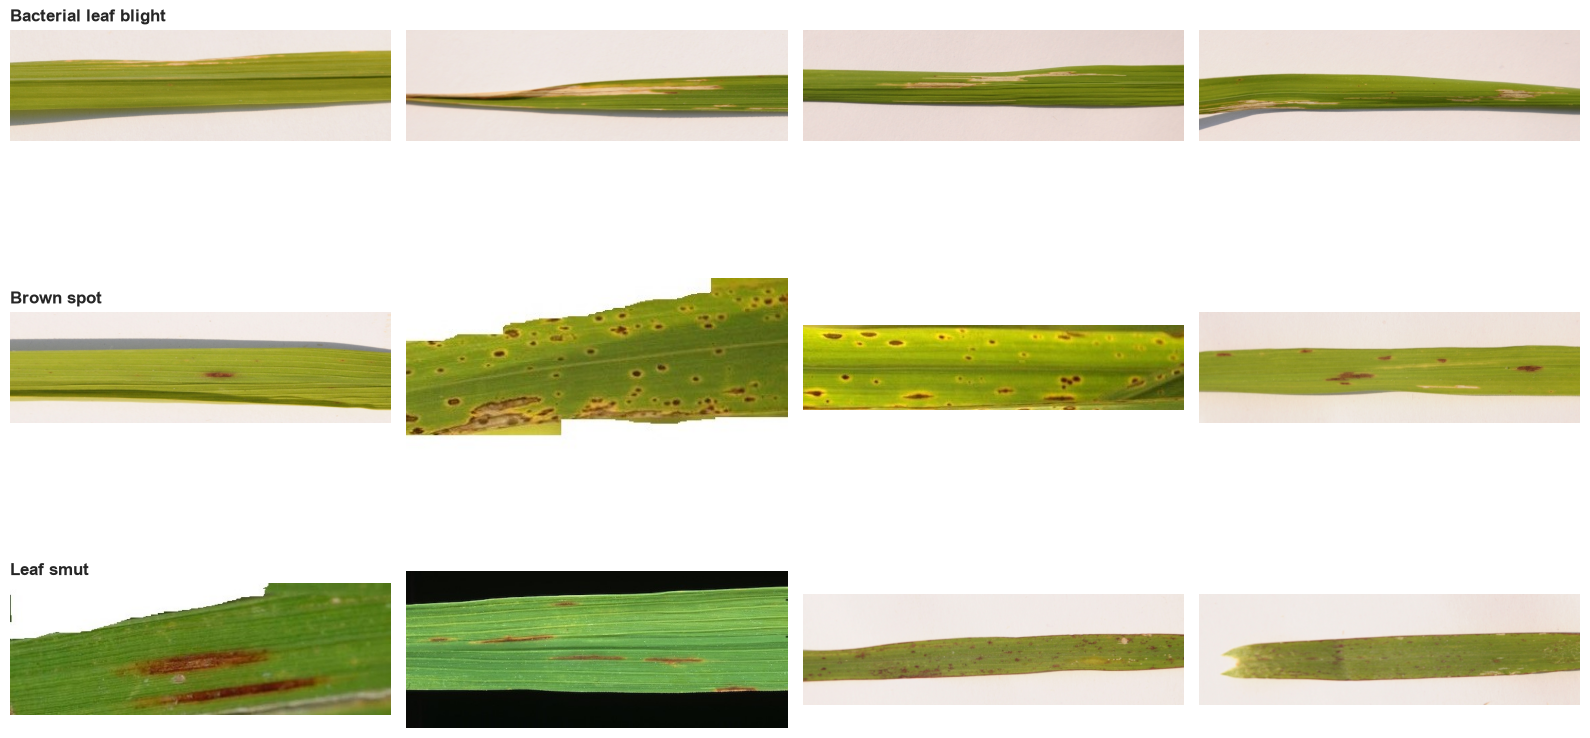

In [6]:
def show_samples(n=4):
    fig, axes = plt.subplots(len(CLASSES), n, figsize=(4 * n, 3.2 * len(CLASSES)))
    for r, cname in enumerate(CLASSES):
        sub = df[df.label == cname].sample(n, random_state=SEED)
        for c, p in enumerate(sub.path):
            axes[r, c].imshow(Image.open(p).convert("RGB"))
            axes[r, c].axis("off")
            if c == 0:
                axes[r, c].set_title(cname, loc="left", fontweight="bold")
    plt.tight_layout(); plt.show()
show_samples()

### 2.2)**Insight (sample images):**

 Most images show a single leaf photographed against a plain light background, and the images are mostly wide strips. Brown spot appears as many small round brown spots, sometimes with a yellow halo; Leaf smut appears as dark brown to black streaks and specks; Bacterial leaf blight appears as pale yellow-brown streaks and is the least visible. Brown spot and Leaf smut look similar (small dark marks on green leaf) and are likely to be confused by the model. In the wide images the lesions occupy a small fraction of the picture, so shrinking them to a small square input may lose detail. A few images have unusual backgrounds (black) or jagged edges, so brightness and geometric augmentation are justified, and background could act as a shortcut.

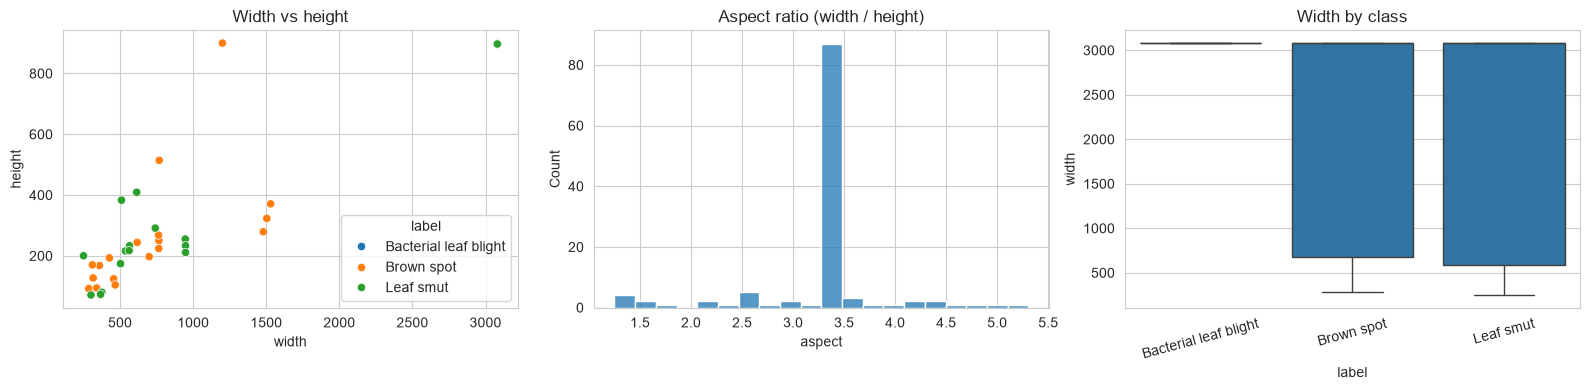

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x="width", y="height", hue="label", ax=ax[0]); ax[0].set_title("Width vs height")
sns.histplot(df.aspect, bins=20, ax=ax[1]); ax[1].set_title("Aspect ratio (width / height)")
sns.boxplot(data=df, x="label", y="width", ax=ax[2]); ax[2].set_title("Width by class"); ax[2].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

### 2.3)**Insight(Ratio):**
 Image sizes are highly inconsistent (34 unique sizes). About 85 of the 119 images share the same very wide size (3081 x 897, aspect ratio about 3.4) and appear in all three classes; the remaining images are much smaller (widths of roughly 250 to 1500 pixels) and occur only in Brown spot and Leaf smut. All Bacterial leaf blight images are 3081 x 897. Because pretrained models need a fixed square input, all images must be resized, and resizing will distort the wide images unless padding or cropping is used. The presence of low-resolution images in only two classes is also a risk, because a model could use image quality rather than disease appearance as a shortcut.

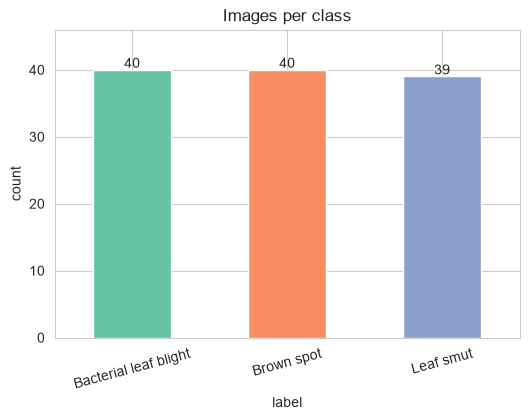

In [8]:
counts = df.label.value_counts().reindex(CLASSES)
ax = counts.plot(kind="bar", color=sns.color_palette("Set2", len(CLASSES)), figsize=(6, 4))
for i, v in enumerate(counts):
    ax.text(i, v + 0.3, str(v), ha="center")
plt.title("Images per class")
plt.ylabel("count")
plt.xticks(rotation=15)
plt.ylim(0, 46)
plt.show()

### 2.4) **Insight (class distribution):**
 The classes are almost perfectly balanced: Bacterial leaf blight 40, Brown spot 40, Leaf smut 39 (119 in total, one fewer than the 120 in the brief). With such a small difference, class weighting is not needed and accuracy is a fair metric, although each test image still moves accuracy by several percentage points because the dataset is so small.

In [9]:

df["big"] = (df.width == 3081) & (df.height == 897)
print(df.groupby("label").big.agg(big_images="sum", total="count"))

                       big_images  total
label                                   
Bacterial leaf blight          40     40
Brown spot                     21     40
Leaf smut                      24     39


### 2.5)**Insight (image sizes):**
 The dataset has 119 images, one fewer than the 120 stated in the brief. The missing image is in Leaf smut (39 images; Bacterial leaf blight and Brown spot have 40 each), so the classes are almost perfectly balanced and class weighting is not needed. Image sizes are highly inconsistent (34 unique sizes). 85 images share the same wide size (3081 x 897, aspect ratio about 3.4) and appear in all three classes (40, 21 and 24 images), so size alone does not identify the class. The remaining 34 images are much smaller (widths of roughly 250 to 1500 pixels) and occur only in Brown spot (19) and Leaf smut (15); no Bacterial leaf blight image is small. A model that ignored the leaves and used only image size would reach about 50% accuracy, so test accuracy needs to be clearly above this. All images are RGB and none are corrupted. Because pretrained models need a fixed square input, all images must be resized, and plain resizing will strongly distort the wide images; padding or cropping should be compared.

In [10]:
IMG_SIZE = (224, 224)

def load_img(p):
    return np.array(Image.open(p).convert("RGB").resize(IMG_SIZE, Image.BILINEAR), dtype=np.uint8)

X_uint8 = np.stack([load_img(p) for p in df.path])
y = df.label_id.values.astype("int32")
print("Image array:", X_uint8.shape, "| labels:", y.shape)

Image array: (119, 224, 224, 3) | labels: (119,)


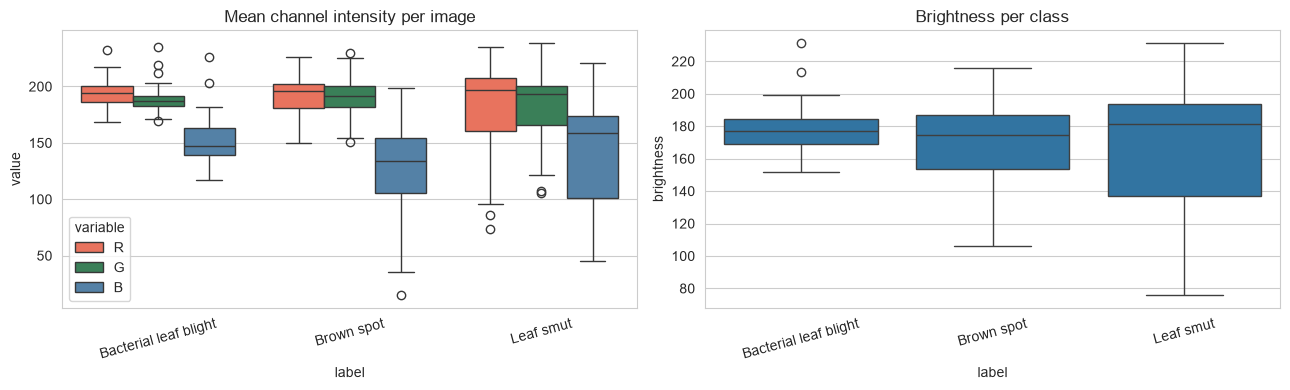

,R,G,B,brightness
label,,,,
Bacterial leaf blight,194.2,188.9,152.2,178.4
Brown spot,191.3,189.5,126.7,169.1
Leaf smut,180.1,181.9,141.4,167.8


In [11]:
stats = pd.DataFrame({"label": df.label,
    "R": X_uint8[..., 0].mean((1, 2)), "G": X_uint8[..., 1].mean((1, 2)), "B": X_uint8[..., 2].mean((1, 2))})
stats["brightness"] = stats[["R", "G", "B"]].mean(1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
stats.melt(id_vars="label", value_vars=["R", "G", "B"]).pipe(
    lambda d: sns.boxplot(data=d, x="label", y="value", hue="variable", ax=ax[0],
                          palette={"R": "tomato", "G": "seagreen", "B": "steelblue"}))
ax[0].set_title("Mean channel intensity per image"); ax[0].tick_params(axis="x", rotation=15)
sns.boxplot(data=stats, x="label", y="brightness", ax=ax[1])
ax[1].set_title("Brightness per class"); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()
display(stats.groupby("label")[["R", "G", "B", "brightness"]].mean().round(1))

### 2.6)**Insight (colour and brightness):** 
Red and green intensities are high and similar across the three classes, while blue is lower, as expected for green leaves on a light background. Brown spot has the lowest mean blue (about 127), consistent with its yellow-brown appearance; Bacterial leaf blight has the highest blue (about 152) and the most uniform brightness, suggesting a consistent pale background. Leaf smut has the widest brightness range (about 75 to 230), including very dark images with black backgrounds. Mean brightness is similar across classes (168 to 178), so colour alone does not separate the classes and the model must rely on lesion shape and texture. The large brightness variation within classes justifies brightness and contrast augmentation, and the background differences are a possible shortcut that we will check during error analysis.

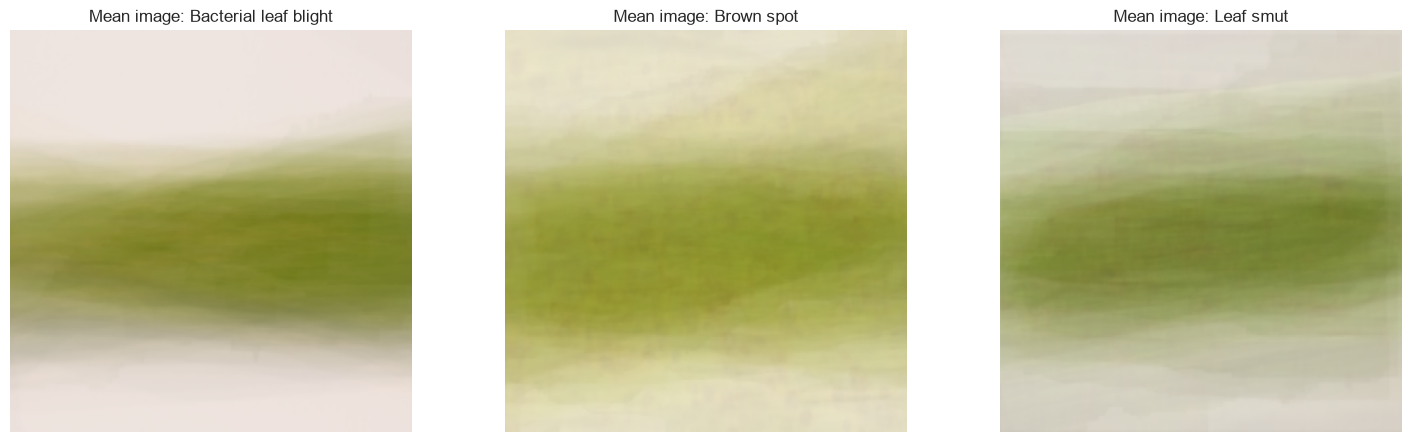

In [12]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(5 * len(CLASSES), 4.5))
for i, cname in enumerate(CLASSES):
    axes[i].imshow(X_uint8[y == i].mean(0).astype("uint8"))
    axes[i].set_title("Mean image: " + cname)
    axes[i].axis("off")
plt.tight_layout(); plt.show()

### 2.7)**Insight (mean images):** 
In all three classes the average image is a horizontal green band across the centre, so leaves are generally horizontal and centred. Lesions do not appear in the averages because they occur in different places on each leaf, so the classes must be distinguished by lesion shape and texture rather than position. Bacterial leaf blight has the sharpest average on a plain pale background, reflecting its uniform image format; Brown spot is the blurriest and most yellow, reflecting more varied framing; Leaf smut is darker and greyer, consistent with its dark-background images. These differences in background and framing are a possible shortcut for the model and will be checked during error analysis.

### 2.8 Summary of the data analysis

- **Size and balance:** 119 images in 3 classes (40 / 40 / 39), one fewer than the brief states. Classes are almost perfectly balanced.
- **Quality:** all files open correctly, all are RGB, none are corrupted.
- **Image sizes:** very inconsistent (34 unique sizes). 85 images are 3081 x 897; the other 34 are much smaller and occur only in Brown spot and Leaf smut.
- **Appearance:** Brown spot shows small round brown spots; Leaf smut shows dark streaks and specks; Bacterial leaf blight shows faint pale streaks. Brown spot and Leaf smut look similar.
- **Colour:** mean colour and brightness are similar across classes, so the model must learn lesion shape and texture. Brightness varies widely inside classes (some black backgrounds).
- **Implications for modelling:** all images need resizing to a fixed square size; lesions are small relative to the image; the dataset is tiny (119 images), so transfer learning and data augmentation are essential, and evaluation needs care because each test image moves accuracy by several percentage points.

## 3. Train / validation / test split

The data is split **before** any augmentation, so that altered copies of the same image can never appear in both training and test sets (data leakage). The split is **stratified**, so each subset keeps the same class proportions.

- Train (70%): used to learn
- Validation (15%): used to choose settings and models
- Test (15%): used only for the final reported results

In [13]:
from sklearn.model_selection import train_test_split

X = X_uint8.astype("float32")     # raw 0-255 values; each pretrained model applies its own scaling later

idx = np.arange(len(df))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=y[tmp_idx], random_state=SEED)

Xtr, ytr = X[tr_idx], y[tr_idx]
Xva, yva = X[va_idx], y[va_idx]
Xte, yte = X[te_idx], y[te_idx]

split_tbl = pd.DataFrame({
    "train": np.bincount(ytr, minlength=len(CLASSES)),
    "val":   np.bincount(yva, minlength=len(CLASSES)),
    "test":  np.bincount(yte, minlength=len(CLASSES))}, index=CLASSES)
split_tbl.loc["TOTAL"] = split_tbl.sum()
display(split_tbl)

,train,val,test
Bacterial leaf blight,28,6,6
Brown spot,28,6,6
Leaf smut,27,6,6
TOTAL,83,18,18


**Caveat:** the validation and test sets contain only about 18 images each (about 6 per class), so one image changes accuracy by about 5.5 percentage points. Results from a single split are therefore noisy; stratified k-fold cross-validation is used later to check the final model.

## 4. Building blocks for the models

Three ideas are used in every experiment:

- **Data augmentation:** random flips, rotations, zooms, shifts and brightness/contrast changes applied to training images, creating many slightly different versions of each photo. It is applied **only while training**, and never to validation or test images.
- **Transfer learning:** instead of learning from 83 images from scratch, we start from a network already trained on millions of images (ImageNet) and adapt it to rice leaves.
- **Overfitting controls:** dropout, early stopping and learning-rate reduction, because with so few images a model can memorise the training set.

In [15]:
AUG_CONFIGS = {
    "none":       lambda: [],
    "flip":       lambda: [layers.RandomFlip("horizontal_and_vertical")],
    "rotation":   lambda: [layers.RandomRotation(0.15)],
    "zoom":       lambda: [layers.RandomZoom(0.2)],
    "shift":      lambda: [layers.RandomTranslation(0.15, 0.15)],
    "brightness": lambda: [layers.RandomBrightness(0.2, value_range=(0, 255))],
    "contrast":   lambda: [layers.RandomContrast(0.2)],
    "combined":   lambda: [layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(0.15),
                           layers.RandomZoom(0.2), layers.RandomTranslation(0.1, 0.1),
                           layers.RandomBrightness(0.2, value_range=(0, 255)), layers.RandomContrast(0.2)],
}
print("Augmentation settings:", list(AUG_CONFIGS))

Augmentation settings: ['none', 'flip', 'rotation', 'zoom', 'shift', 'brightness', 'contrast', 'combined']


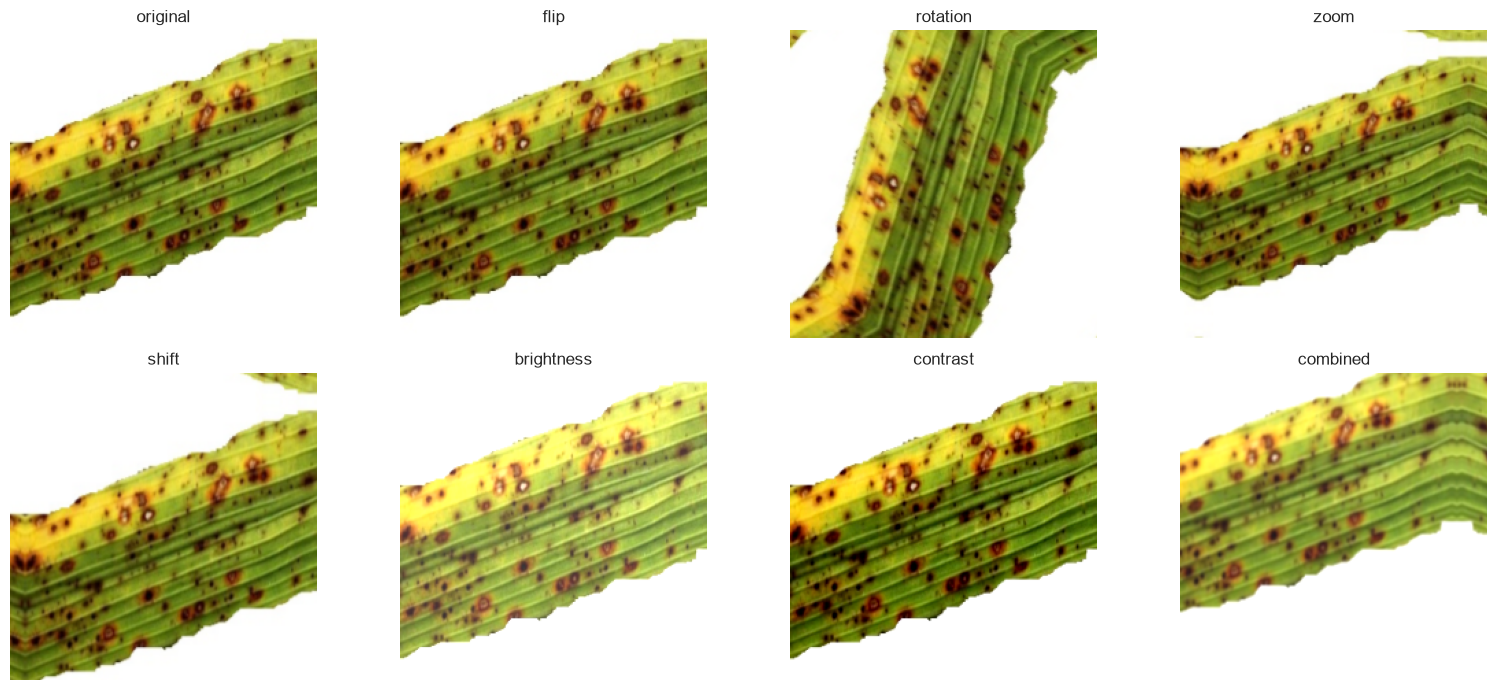

In [16]:
cls = CLASSES.index("Brown spot")
x = X[np.where(y == cls)[0][1]][None]          # one Brown spot image, with a batch dimension

fig, axes = plt.subplots(2, 4, figsize=(16, 7)); axes = axes.ravel()
axes[0].imshow(x[0].astype("uint8")); axes[0].set_title("original"); axes[0].axis("off")
for ax, k in zip(axes[1:], [k for k in AUG_CONFIGS if k != "none"]):
    out = x
    for layer in AUG_CONFIGS[k]():
        out = layer(out, training=True)           # training=True switches the random change on
    ax.imshow(np.clip(np.array(out[0]), 0, 255).astype("uint8"))
    ax.set_title(k); ax.axis("off")
plt.tight_layout(); plt.show()

**Insight (augmentation examples):** Flips and rotations change leaf orientation, zoom and shift change lesion size and position, and brightness/contrast mimic lighting differences. The lesions remain visible under all settings, so these transformations are realistic for field photos.  Rotation and shift fill empty corners with mirrored image content, which is acceptable but slightly unnatural. The combined setting is the strongest distortion, so whether it helps or hurts will be tested experimentally.

In [17]:
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)

A = keras.applications
BACKBONES = {
    "MobileNetV2":    (A.MobileNetV2,    A.mobilenet_v2.preprocess_input),
    "ResNet50":       (A.ResNet50,       A.resnet50.preprocess_input),
    "VGG16":          (A.VGG16,          A.vgg16.preprocess_input),
    "DenseNet121":    (A.DenseNet121,    A.densenet.preprocess_input),
    "EfficientNetB0": (A.EfficientNetB0, A.efficientnet.preprocess_input),
}

def build_transfer(name, aug_fn):
    ctor, prep = BACKBONES[name]
    base = ctor(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
    base.trainable = False                          # stage 1: keep the pretrained knowledge fixed
    inp = keras.Input((*IMG_SIZE, 3))
    x = inp
    for l in aug_fn():                              # augmentation (active only while training)
        x = l(x)
    x = layers.Lambda(prep, name="preprocess")(x)   # the scaling this particular network expects
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)                      # randomly switches off neurons to limit overfitting
    out = layers.Dense(len(CLASSES), activation="softmax")(x)
    return keras.Model(inp, out, name=name), base

def build_cnn(aug_fn):
    # a small CNN trained from scratch: the baseline with no pretrained knowledge
    inp = keras.Input((*IMG_SIZE, 3))
    x = inp
    for l in aug_fn():
        x = l(x)
    x = layers.Rescaling(1 / 255.0)(x)
    for f in (32, 64, 128):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.ReLU()(x); x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(len(CLASSES), activation="softmax")(x)
    return keras.Model(inp, out, name="CustomCNN"), None
print("Model builders defined:", list(BACKBONES) + ["CustomCNN"])

Model builders defined: ['MobileNetV2', 'ResNet50', 'VGG16', 'DenseNet121', 'EfficientNetB0', 'CustomCNN']


In [18]:
def train_eval(name, aug_key, data, epochs=20, fine_tune=False, ft_epochs=10, n_unfreeze=30,
               seed=SEED, lr=1e-3, verbose=0):
    keras.backend.clear_session(); set_seed(seed)
    Xtr, ytr, Xva, yva, Xte, yte = data
    aug_fn = AUG_CONFIGS[aug_key]
    model, base = build_cnn(aug_fn) if name == "CustomCNN" else build_transfer(name, aug_fn)

    cbs = lambda: [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
                   keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7)]
    t0 = time.time()
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=16, callbacks=cbs(), verbose=verbose)
    hist = {k: list(v) for k, v in h1.history.items()}
    stage1_val = model.evaluate(Xva, yva, verbose=0)[1]

    if fine_tune and base is not None:              # stage 2: gently adapt the last layers of the backbone
        base.trainable = True
        for l in base.layers[:-n_unfreeze]:
            l.trainable = False
        for l in base.layers:
            if isinstance(l, layers.BatchNormalization):
                l.trainable = False
        model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        h2 = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=ft_epochs, batch_size=16, callbacks=cbs(), verbose=verbose)
        for k, v in h2.history.items():
            hist.setdefault(k, []).extend(v)
    train_time = time.time() - t0

    tr_acc = model.evaluate(Xtr, ytr, verbose=0)[1]
    va_acc = model.evaluate(Xva, yva, verbose=0)[1]
    t1 = time.time(); prob = model.predict(Xte, verbose=0)
    inf_ms = (time.time() - t1) / len(Xte) * 1000
    pred = prob.argmax(1)
    return dict(model=model, history=hist, name=name, aug=aug_key,
                train_acc=tr_acc, stage1_val_acc=stage1_val, val_acc=va_acc,
                test_acc=accuracy_score(yte, pred), test_f1=f1_score(yte, pred, average="macro"),
                params_M=model.count_params() / 1e6, train_time_s=train_time, inference_ms_per_img=inf_ms,
                y_pred=pred, y_prob=prob)

DATA = (Xtr, ytr, Xva, yva, Xte, yte)
print("train_eval defined")

train_eval defined


## 5. Quick sanity check

One MobileNetV2 model (frozen backbone, combined augmentation, at most 10 epochs) was trained to confirm the pipeline works and to measure training time. Result: train accuracy 94.0%, validation accuracy 88.9%, test accuracy 83.3% (15 of 18 test images), trained in about 30 seconds on a CPU. This single run is not used for any conclusion because the validation and test sets are very small.

## 6. Data augmentation study

The same model (MobileNetV2, frozen backbone) is trained with **no augmentation**, with **each technique alone**, and with **all techniques combined**. Each setting is repeated with 3 different random seeds, because a single run on 18 validation images is too noisy. The best setting is chosen on **validation** accuracy; the test set stays untouched.

In [20]:
AUG_SEEDS = [1, 2, 3]
aug_rows = []
for key in AUG_CONFIGS:
    vals, trs = [], []
    for s in AUG_SEEDS:
        res = train_eval("MobileNetV2", key, DATA, epochs=15, fine_tune=False, seed=s)
        vals.append(res["val_acc"]); trs.append(res["train_acc"])
    aug_rows.append(dict(augmentation=key,
                         val_acc_mean=np.mean(vals), val_acc_std=np.std(vals),
                         train_acc_mean=np.mean(trs), gap=np.mean(trs) - np.mean(vals)))
    print(f"{key:11s} val = {np.mean(vals):.3f} +/- {np.std(vals):.3f}   (train {np.mean(trs):.3f})")

aug_df = pd.DataFrame(aug_rows).sort_values("val_acc_mean", ascending=False).reset_index(drop=True)
display(aug_df.round(3))

none        val = 1.000 +/- 0.000   (train 1.000)
flip        val = 0.926 +/- 0.052   (train 0.988)
rotation    val = 0.944 +/- 0.000   (train 0.980)
zoom        val = 0.981 +/- 0.026   (train 0.992)
shift       val = 0.981 +/- 0.026   (train 0.996)
brightness  val = 0.981 +/- 0.026   (train 1.000)
contrast    val = 0.963 +/- 0.026   (train 1.000)
combined    val = 0.944 +/- 0.045   (train 0.932)


,augmentation,val_acc_mean,val_acc_std,train_acc_mean,gap
0,none,1.000,0.000,1.000,0.000
1,zoom,0.981,0.026,0.992,0.010
2,brightness,0.981,0.026,1.000,0.019
3,shift,0.981,0.026,0.996,0.015
4,contrast,0.963,0.026,1.000,0.037
5,combined,0.944,0.045,0.932,-0.013
6,rotation,0.944,0.000,0.980,0.035
7,flip,0.926,0.052,0.988,0.062


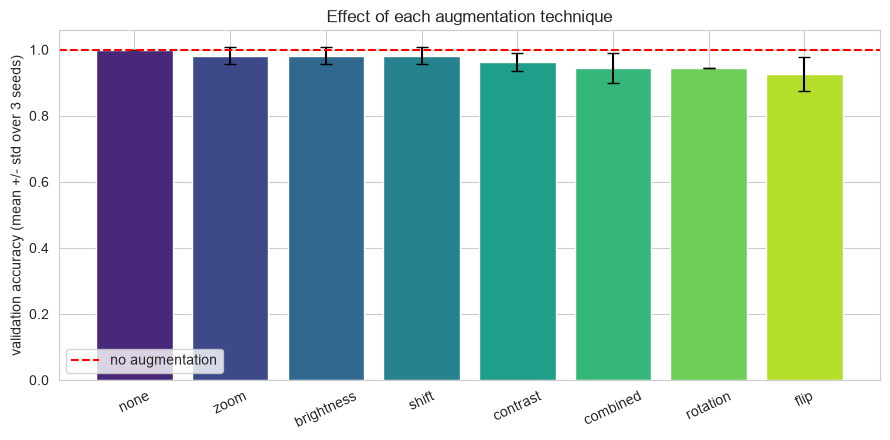

Best augmentation setting on validation accuracy: none


In [21]:
plt.figure(figsize=(9, 4.5))
plt.bar(aug_df.augmentation, aug_df.val_acc_mean, yerr=aug_df.val_acc_std, capsize=4,
        color=sns.color_palette("viridis", len(aug_df)))
none_acc = aug_df.loc[aug_df.augmentation == "none", "val_acc_mean"].values[0]
plt.axhline(none_acc, color="red", ls="--", label="no augmentation")
plt.ylabel("validation accuracy (mean +/- std over 3 seeds)")
plt.title("Effect of each augmentation technique")
plt.xticks(rotation=25); plt.legend(); plt.tight_layout(); plt.show()

BEST_AUG = aug_df.loc[0, "augmentation"]
print("Best augmentation setting on validation accuracy:", BEST_AUG)

### 6.1 Result of the first augmentation experiment

With 18 validation images, no augmentation scored highest (about 100%) and the augmented settings scored 92% to 98%. These differences amount to one or two images and the error bars overlap, so they are within noise. The validation set is too small, and pretrained MobileNetV2 is already near the ceiling, to show any benefit. The experiment is therefore repeated with stratified 5-fold cross-validation on the 101 train + validation images, keeping the 18 test images untouched.

In [23]:
from sklearn.model_selection import StratifiedKFold

pool_idx = np.concatenate([tr_idx, va_idx])       # train + validation only; the test set is NOT used here
Xp, yp = X[pool_idx], y[pool_idx]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_rows = []
for key in AUG_CONFIGS:
    fold_acc = []
    for a, b in skf.split(Xp, yp):
        ia, iv = train_test_split(a, test_size=0.15, stratify=yp[a], random_state=SEED)
        fold_data = (Xp[ia], yp[ia], Xp[iv], yp[iv], Xp[b], yp[b])   # b = images held out in this fold
        res = train_eval("MobileNetV2", key, fold_data, epochs=15, fine_tune=False, seed=SEED)
        fold_acc.append(res["test_acc"])                              # accuracy on the held-out fold
    cv_rows.append(dict(augmentation=key, cv_acc_mean=np.mean(fold_acc), cv_acc_std=np.std(fold_acc)))
    print(f"{key:11s} CV accuracy = {np.mean(fold_acc):.3f} +/- {np.std(fold_acc):.3f}")

cv_aug = pd.DataFrame(cv_rows).sort_values("cv_acc_mean", ascending=False).reset_index(drop=True)
display(cv_aug.round(3))

none        CV accuracy = 0.860 +/- 0.107
flip        CV accuracy = 0.860 +/- 0.147
rotation    CV accuracy = 0.831 +/- 0.125
zoom        CV accuracy = 0.870 +/- 0.133
shift       CV accuracy = 0.850 +/- 0.123
brightness  CV accuracy = 0.860 +/- 0.147
contrast    CV accuracy = 0.850 +/- 0.152
combined    CV accuracy = 0.831 +/- 0.104


,augmentation,cv_acc_mean,cv_acc_std
0,zoom,0.870,0.133
1,flip,0.860,0.147
2,brightness,0.860,0.147
3,none,0.860,0.107
4,contrast,0.850,0.152
5,shift,0.850,0.123
6,rotation,0.831,0.125
7,combined,0.831,0.104


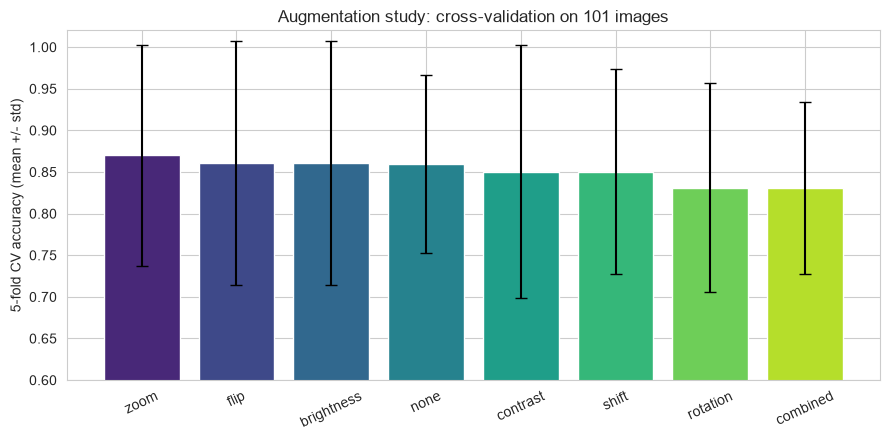

In [24]:
plt.figure(figsize=(9, 4.5))
plt.bar(cv_aug.augmentation, cv_aug.cv_acc_mean, yerr=cv_aug.cv_acc_std, capsize=4,
        color=sns.color_palette("viridis", len(cv_aug)))
plt.ylim(0.6, 1.02)
plt.ylabel("5-fold CV accuracy (mean +/- std)")
plt.title("Augmentation study: cross-validation on 101 images")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()

In [25]:
BEST_AUG = "zoom"
print("Augmentation used for the model comparison:", BEST_AUG)

Augmentation used for the model comparison: zoom


### 6.2 Result of the cross-validated augmentation study

Using stratified 5-fold cross-validation on 101 images (the 18 test images were not used), mean accuracy ranged from 0.831 (rotation, combined) to 0.870 (zoom); no augmentation scored 0.860. The differences are 1 to 4 percentage points, while accuracy varies by 10 to 15 points between folds (each fold holds about 20 images), so **none of the techniques is distinguishable from the no-augmentation baseline**. Augmentation therefore did not give a measurable benefit in this setup (frozen pretrained MobileNetV2 trained for 15 epochs). Possible reasons: the pretrained features are already strong, the head trains for only a few epochs, and strong transformations (rotation with mirrored corners, combined) make training harder. Zoom is used in the following experiments because it scored highest and addresses a real source of variation (lesion size and framing differ between photos), not because the evidence for it is strong.

**Note on the first experiment:** on the 18 validation images accuracy appeared to be 92% to 100%; cross-validation shows the true accuracy is about 85%, so the small validation set was optimistic. The y-axis of the cross-validation chart starts at 0.6 to make differences visible, which exaggerates them visually.

In [44]:
def load_img_pad(p, size=224):
    im = Image.open(p).convert("RGB"); w, h = im.size; s = max(w, h)
    fill = tuple(int(v) for v in np.asarray(im).reshape(-1, 3).mean(0))
    canvas = Image.new("RGB", (s, s), fill); canvas.paste(im, ((s - w) // 2, (s - h) // 2))
    return np.array(canvas.resize((size, size), Image.BILINEAR), dtype=np.uint8)

X_pad = np.stack([load_img_pad(p) for p in df.path]).astype("float32")

def cv_on(Xarr, name="MobileNetV2", fine_tune=False):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED); acc = []
    for a, b in skf.split(Xarr, yp):
        ia, iv = train_test_split(a, test_size=0.15, stratify=yp[a], random_state=SEED)
        r = train_eval(name, BEST_AUG, (Xarr[ia], yp[ia], Xarr[iv], yp[iv], Xarr[b], yp[b]),
                       epochs=20, fine_tune=fine_tune, seed=SEED)
        acc.append(r["test_acc"])
    return np.mean(acc), np.std(acc)

for label, arr in [("squash (current)", Xp), ("pad to square", X_pad[pool_idx])]:
    m, s = cv_on(arr); print(f"{label:18s} CV acc = {m:.3f} +/- {s:.3f}")

squash (current)   CV acc = 0.860 +/- 0.124
pad to square      CV acc = 0.840 +/- 0.097


**Insight (resize strategy):** With 5-fold cross-validation on 101 images, squashing gave an accuracy of 0.860 (+/- 0.124) and padding to a square gave 0.840 (+/- 0.097). The difference of 2 points is about two images out of 101 and is far smaller than the fold-to-fold spread, so the two methods are indistinguishable and the simpler squash method was kept. Padding preserves the real leaf shape but shrinks the lesions in the 224 x 224 input, which probably offsets the benefit.

### 6.3 Resize strategy: squash vs pad

Most images are very wide (3081 x 897). Plain resizing to 224 x 224 ("squash") distorts them. Here it is compared with **padding to a square** (the leaf keeps its real shape, with a plain border added) using the same model, the same 5-fold cross-validation on the 101 train and validation images, and the same settings. The 18 test images are not used.

,model,cv_pooled,train_acc,test_acc,test_F1,params_M,train_time_s,gap (train-test)
0,ResNet50 (fine-tuned),0.911,1.0,0.833,0.831,23.594,185.971,0.167
1,MobileNetV2 (fine-tuned),0.891,1.0,0.944,0.944,2.262,73.376,0.056
2,MobileNetV2 (frozen),0.861,1.0,0.889,0.892,2.262,45.086,0.111
3,EfficientNetB0 (fine-tuned),0.861,1.0,0.833,0.833,4.053,103.936,0.167


## 7. Model comparison

Six models are compared: a small CNN trained from scratch (CustomCNN) and five ImageNet-pretrained networks (MobileNetV2, ResNet50, VGG16, DenseNet121, EfficientNetB0). All use the augmentation chosen in Section 6. First, the time per epoch of each model is measured on this CPU so the experiments can be planned.

In [26]:
MODEL_NAMES = ["CustomCNN", "MobileNetV2", "EfficientNetB0", "ResNet50", "DenseNet121", "VGG16"]
timing = {}
for m in MODEL_NAMES:
    t0 = time.time()
    r = train_eval(m, BEST_AUG, DATA, epochs=1, fine_tune=False, verbose=0)
    timing[m] = dict(seconds_per_epoch=time.time() - t0, params_M=r["params_M"])
    print(f"{m:15s} {timing[m]['seconds_per_epoch']:6.1f} s/epoch   {r['params_M']:.1f} M parameters")

CustomCNN         14.8 s/epoch   0.1 M parameters
MobileNetV2       29.5 s/epoch   2.3 M parameters
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
EfficientNetB0    37.8 s/epoch   4.1 M parameters
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
ResNet50          47.2 s/epoch   23.6 M parameters
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
DenseNet121       57.9 s/epoch   7.0 M parameters
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
VGG16             62.6 s/epoch   14.7 M parameters


In [29]:
MODEL_NAMES = ["CustomCNN", "MobileNetV2", "EfficientNetB0", "ResNet50", "DenseNet121", "VGG16"]
results = {}
for m in MODEL_NAMES:
    r = train_eval(m, BEST_AUG, DATA, epochs=30 if m == "CustomCNN" else 20, fine_tune=False, seed=SEED)
    results[m] = r
    print(f"{m:15s} train={r['train_acc']:.3f}  val={r['val_acc']:.3f}  test={r['test_acc']:.3f}  "
          f"time={r['train_time_s']:.0f}s")

CustomCNN       train=0.410  val=0.333  test=0.500  time=72s
MobileNetV2     train=1.000  val=1.000  test=0.889  time=45s
EfficientNetB0  train=1.000  val=1.000  test=0.778  time=61s
ResNet50        train=1.000  val=0.944  test=0.833  time=120s
DenseNet121     train=0.952  val=0.944  test=0.778  time=176s
VGG16           train=0.880  val=0.833  test=0.667  time=647s


In [30]:
cmp = pd.DataFrame([{
    "model": m,
    "params_M": r["params_M"],
    "train_acc": r["train_acc"],
    "val_acc": r["val_acc"],
    "test_acc": r["test_acc"],
    "test_macro_F1": r["test_f1"],
    "gap (train-val)": r["train_acc"] - r["val_acc"],
    "train_time_s": r["train_time_s"],
    "inference_ms/img": r["inference_ms_per_img"],
} for m, r in results.items()])
cmp = cmp.sort_values(["val_acc", "params_M"], ascending=[False, True]).reset_index(drop=True)
display(cmp.round(3))

,model,params_M,train_acc,val_acc,test_acc,test_macro_F1,gap (train-val),train_time_s,inference_ms/img
0,MobileNetV2,2.262,1.000,1.000,0.889,0.892,0.000,45.086,120.269
1,EfficientNetB0,4.053,1.000,1.000,0.778,0.777,0.000,61.177,113.080
2,DenseNet121,7.041,0.952,0.944,0.778,0.768,0.007,176.076,302.522
3,ResNet50,23.594,1.000,0.944,0.833,0.831,0.056,120.105,178.351
4,VGG16,14.716,0.880,0.833,0.667,0.646,0.046,647.460,157.780
5,CustomCNN,0.094,0.410,0.333,0.500,0.401,0.076,72.201,18.750


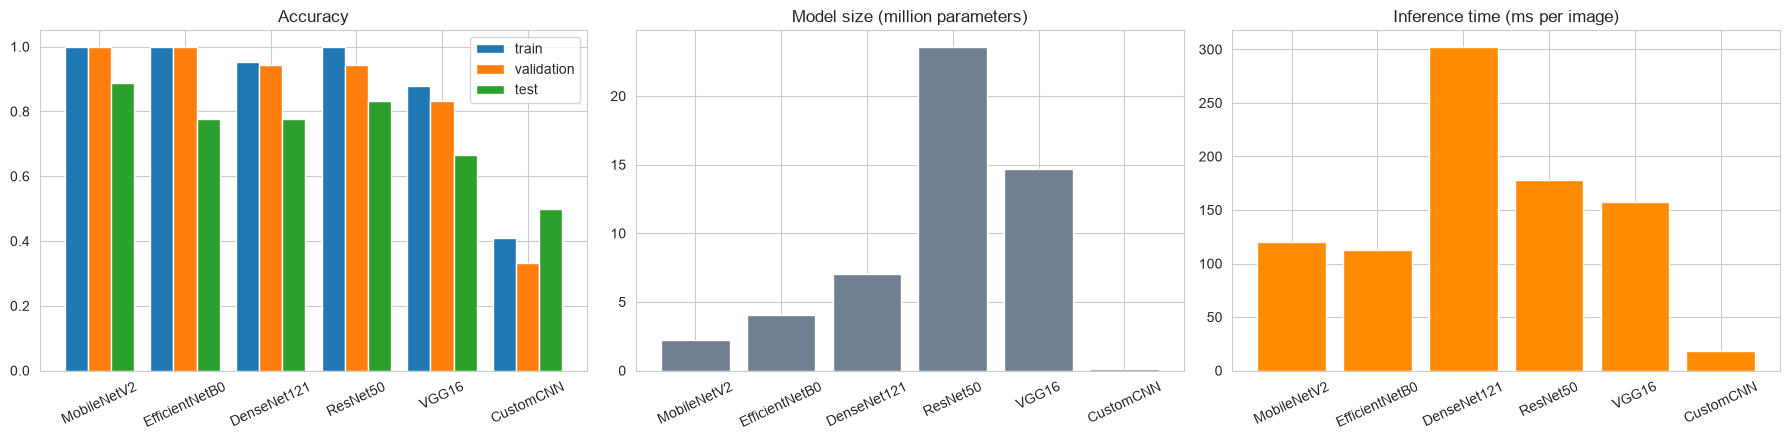

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
w, xs = 0.27, np.arange(len(cmp))
ax[0].bar(xs - w, cmp.train_acc, w, label="train")
ax[0].bar(xs, cmp.val_acc, w, label="validation")
ax[0].bar(xs + w, cmp.test_acc, w, label="test")
ax[0].set_xticks(xs); ax[0].set_xticklabels(cmp.model, rotation=25)
ax[0].set_ylim(0, 1.05); ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].bar(cmp.model, cmp.params_M, color="slategray")
ax[1].set_title("Model size (million parameters)"); ax[1].tick_params(axis="x", rotation=25)
ax[2].bar(cmp.model, cmp["inference_ms/img"], color="darkorange")
ax[2].set_title("Inference time (ms per image)"); ax[2].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

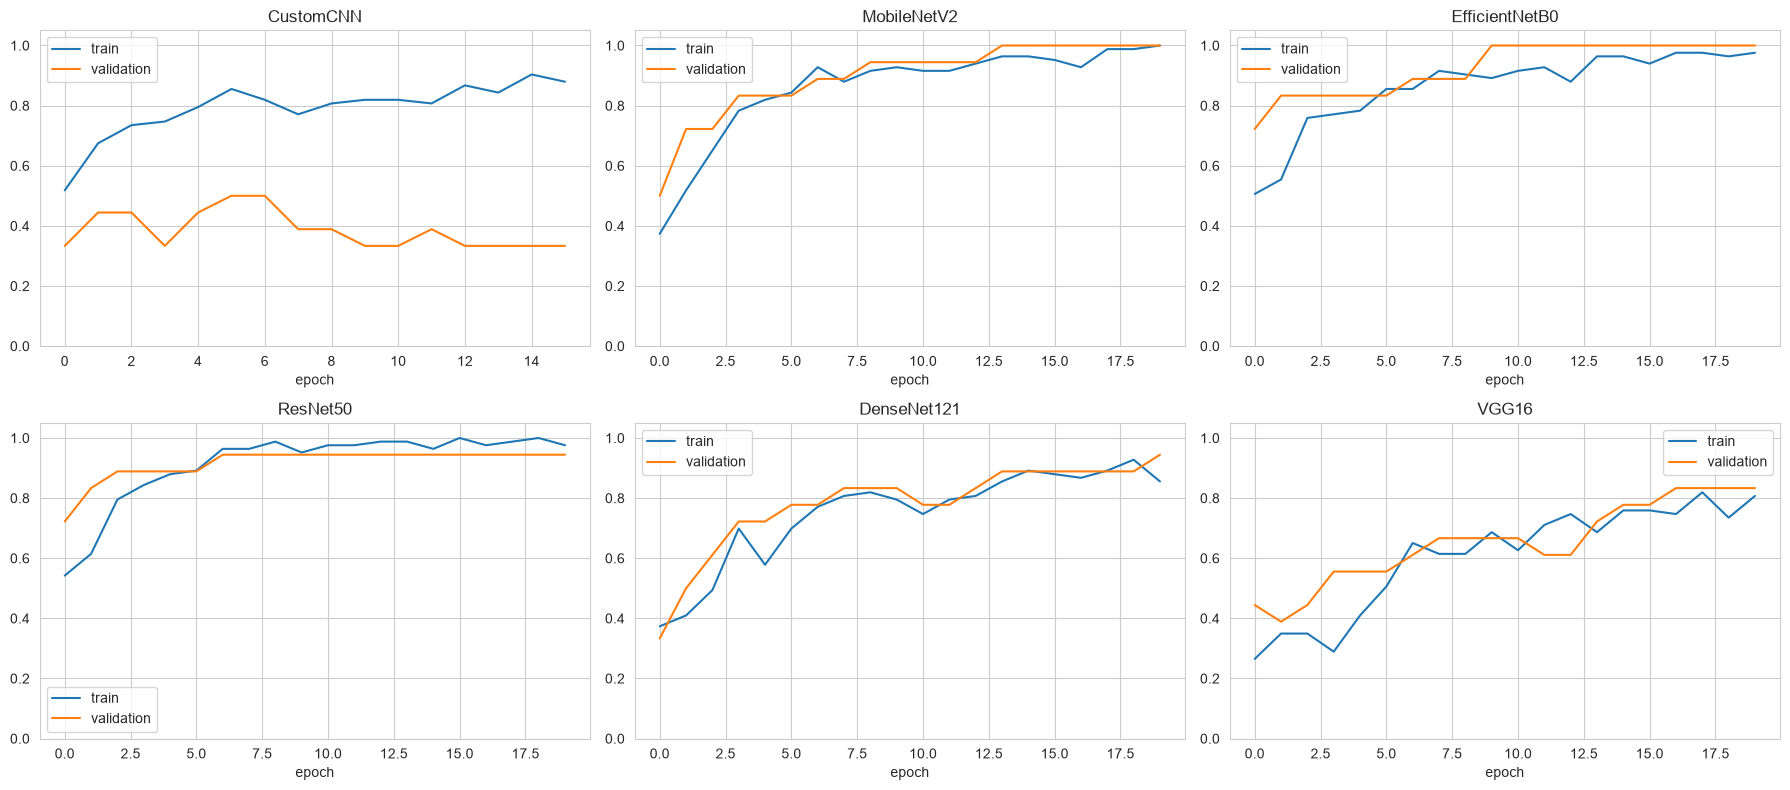

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8)); axes = axes.ravel()
for a, m in zip(axes, MODEL_NAMES):
    h = results[m]["history"]
    a.plot(h["accuracy"], label="train"); a.plot(h["val_accuracy"], label="validation")
    a.set_title(m); a.set_xlabel("epoch"); a.set_ylim(0, 1.05); a.legend()
plt.tight_layout(); plt.show()

In [33]:
cmp["gap (train-test)"] = cmp.train_acc - cmp.test_acc
display(cmp.round(3))

,model,params_M,train_acc,val_acc,test_acc,test_macro_F1,gap (train-val),train_time_s,inference_ms/img,gap (train-test)
0,MobileNetV2,2.262,1.000,1.000,0.889,0.892,0.000,45.086,120.269,0.111
1,EfficientNetB0,4.053,1.000,1.000,0.778,0.777,0.000,61.177,113.080,0.222
2,DenseNet121,7.041,0.952,0.944,0.778,0.768,0.007,176.076,302.522,0.174
3,ResNet50,23.594,1.000,0.944,0.833,0.831,0.056,120.105,178.351,0.167
4,VGG16,14.716,0.880,0.833,0.667,0.646,0.046,647.460,157.780,0.213
5,CustomCNN,0.094,0.410,0.333,0.500,0.401,0.076,72.201,18.750,-0.090


**Insight (model comparison, frozen backbones):** All five ImageNet-pretrained models learned the task, while the CustomCNN trained from scratch did not (validation accuracy 0.33, equal to chance), so with only 83 training images pretrained features are essential. MobileNetV2 scored highest on validation (1.000, tied with EfficientNetB0, and chosen by the smaller-size tie-break) and also on test (0.889, 16 of 18 images) while being the smallest pretrained model (2.3 M parameters). ResNet50, EfficientNetB0 and DenseNet121 scored 14 to 15 of 18 test images; differences of one or two images are not meaningful with 18 test images. VGG16 was clearly weaker (0.667) and by far the slowest to train (647 s); its curves were still rising, so it was probably undertrained. The train-minus-validation gap looks near zero for most models only because the 18 validation images are easy (the cross-validated accuracy in Section 6 was about 86%); the train-minus-test gap (up to 0.22) shows the real overfitting. These are single-run results, so the final model will be chosen using cross-validation.

In [34]:
FT_MODELS = ["MobileNetV2", "EfficientNetB0", "ResNet50"]
ft_results = {}
for m in FT_MODELS:
    r = train_eval(m, BEST_AUG, DATA, epochs=20, fine_tune=True, ft_epochs=10, seed=SEED)
    ft_results[m] = r
    print(f"{m:15s} val={r['val_acc']:.3f}  test={r['test_acc']:.3f}  time={r['train_time_s']:.0f}s")

ft_tbl = pd.DataFrame([{
    "model": m,
    "frozen_val": results[m]["val_acc"], "finetuned_val": ft_results[m]["val_acc"],
    "frozen_test": results[m]["test_acc"], "finetuned_test": ft_results[m]["test_acc"],
    "finetune_time_s": ft_results[m]["train_time_s"]} for m in FT_MODELS])
display(ft_tbl.round(3))

MobileNetV2     val=1.000  test=0.944  time=73s
EfficientNetB0  val=1.000  test=0.833  time=104s
ResNet50        val=1.000  test=0.833  time=186s


,model,frozen_val,finetuned_val,frozen_test,finetuned_test,finetune_time_s
0,MobileNetV2,1.000,1.0,0.889,0.944,73.376
1,EfficientNetB0,1.000,1.0,0.778,0.833,103.936
2,ResNet50,0.944,1.0,0.833,0.833,185.971


**Insight (fine-tuning):** Fine-tuning the last 30 layers at a low learning rate raised test accuracy by one image for MobileNetV2 (16 to 17 of 18) and EfficientNetB0 (14 to 15 of 18) and left ResNet50 unchanged (15 of 18). All three reached 1.000 validation accuracy, so validation no longer separates them. Gains of one image (5.6 percentage points) are within noise for an 18-image test set, so fine-tuning gives at most a small benefit here, at the cost of 73 to 186 extra seconds of CPU training. The choice between models is therefore made with cross-validation on all 101 training and validation images.

In [35]:
def cv_model(name, fine_tune, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof = np.zeros(len(yp), dtype=int)                  # out-of-fold prediction for every image
    fold_acc = []
    for a, b in skf.split(Xp, yp):
        ia, iv = train_test_split(a, test_size=0.15, stratify=yp[a], random_state=SEED)
        fold_data = (Xp[ia], yp[ia], Xp[iv], yp[iv], Xp[b], yp[b])
        r = train_eval(name, BEST_AUG, fold_data, epochs=20, fine_tune=fine_tune, ft_epochs=10, seed=SEED)
        oof[b] = r["y_pred"]
        fold_acc.append(r["test_acc"])
    return fold_acc, oof

CV_RUNS = [("MobileNetV2", False), ("MobileNetV2", True), ("EfficientNetB0", True), ("ResNet50", True)]
cv_res, oof_preds = [], {}  
for name, ft in CV_RUNS:
    t0 = time.time()
    accs, oof = cv_model(name, ft)
    label = f"{name} ({'fine-tuned' if ft else 'frozen'})"
    oof_preds[label] = oof
    cv_res.append(dict(model=label, cv_acc_mean=np.mean(accs), cv_acc_std=np.std(accs),
                       pooled_acc=(oof == yp).mean(), time_min=(time.time() - t0) / 60))
    print(f"{label:30s} CV acc = {np.mean(accs):.3f} +/- {np.std(accs):.3f}   pooled = {(oof == yp).mean():.3f}   ({(time.time()-t0)/60:.1f} min)")

cv_tbl = pd.DataFrame(cv_res).sort_values("cv_acc_mean", ascending=False).reset_index(drop=True)
display(cv_tbl.round(3))

MobileNetV2 (frozen)           CV acc = 0.860 +/- 0.124   pooled = 0.861   (3.7 min)
MobileNetV2 (fine-tuned)       CV acc = 0.890 +/- 0.111   pooled = 0.891   (5.5 min)
EfficientNetB0 (fine-tuned)    CV acc = 0.860 +/- 0.107   pooled = 0.861   (9.4 min)
ResNet50 (fine-tuned)          CV acc = 0.910 +/- 0.097   pooled = 0.911   (16.0 min)


,model,cv_acc_mean,cv_acc_std,pooled_acc,time_min
0,ResNet50 (fine-tuned),0.91,0.097,0.911,16.048
1,MobileNetV2 (fine-tuned),0.89,0.111,0.891,5.531
2,MobileNetV2 (frozen),0.86,0.124,0.861,3.721
3,EfficientNetB0 (fine-tuned),0.86,0.107,0.861,9.360


**Insight (cross-validation):** Stratified 5-fold cross-validation on the 101 training and validation images (the 18 test images were not used) gave pooled accuracies of 0.911 (ResNet50, fine-tuned), 0.891 (MobileNetV2, fine-tuned), 0.861 (MobileNetV2, frozen) and 0.861 (EfficientNetB0, fine-tuned), i.e. 92, 90, 87 and 87 correct predictions out of 101. The spread between folds is about 0.10 (each fold holds about 20 images), so differences of 2 to 3 images are within noise. This also shows the earlier 100% validation scores were optimistic; realistic accuracy is about 86 to 91%. Fine-tuning improved MobileNetV2 by 3 images (87 to 90), consistent with the one-image gain on the test set, but this is weak evidence. Because ResNet50 is not distinguishably better yet has about ten times more parameters (23.6 M vs 2.3 M) and took about three times longer, **fine-tuned MobileNetV2 is selected** as the final model.

Final model: MobileNetV2 (fine-tuned)
Test accuracy: 0.944   Test macro-F1: 0.944

                       precision    recall  f1-score   support

Bacterial leaf blight      1.000     1.000     1.000         6
           Brown spot      0.857     1.000     0.923         6
            Leaf smut      1.000     0.833     0.909         6

             accuracy                          0.944        18
            macro avg      0.952     0.944     0.944        18
         weighted avg      0.952     0.944     0.944        18



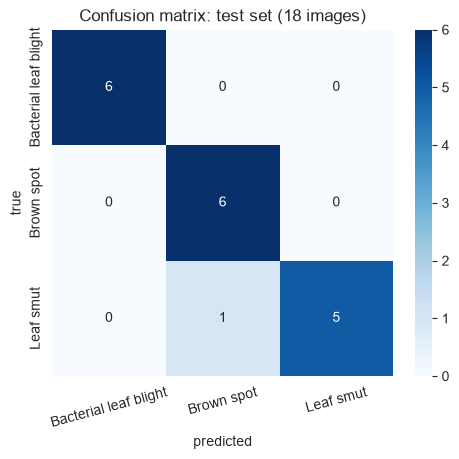

In [36]:
FINAL = ft_results["MobileNetV2"]          # fine-tuned MobileNetV2
print("Final model: MobileNetV2 (fine-tuned)")
print(f"Test accuracy: {FINAL['test_acc']:.3f}   Test macro-F1: {FINAL['test_f1']:.3f}\n")
print(classification_report(yte, FINAL["y_pred"], target_names=CLASSES, digits=3))

cm = confusion_matrix(yte, FINAL["y_pred"])
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix: test set (18 images)")
plt.xticks(rotation=15); plt.show()

                       precision    recall  f1-score   support

Bacterial leaf blight      0.943     0.971     0.957        34
           Brown spot      0.848     0.824     0.836        34
            Leaf smut      0.879     0.879     0.879        33

             accuracy                          0.891       101
            macro avg      0.890     0.891     0.890       101
         weighted avg      0.890     0.891     0.890       101



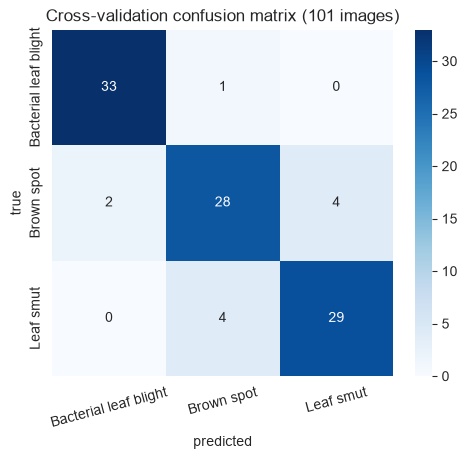

In [37]:
oof = oof_preds["MobileNetV2 (fine-tuned)"]
print(classification_report(yp, oof, target_names=CLASSES, digits=3))
cm_cv = confusion_matrix(yp, oof)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm_cv, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Cross-validation confusion matrix (101 images)")
plt.xticks(rotation=15); plt.show()

In [38]:
FINAL["model"].save_weights("best_model.weights.h5")
with open("class_names.txt", "w") as f:
    f.write("\n".join(CLASSES))
print("Saved: best_model.weights.h5 and class_names.txt")

Saved: best_model.weights.h5 and class_names.txt


**Insight (final evaluation on the test set):** The final model, fine-tuned MobileNetV2, classified 17 of the 18 test images correctly (accuracy 0.944, macro-F1 0.944). All Bacterial leaf blight and Brown spot images were found; the single error was one Leaf smut image predicted as Brown spot (Leaf smut recall 0.833, Brown spot precision 0.857). This is the confusion expected from the sample images, since both diseases appear as small dark marks on green leaves. With only 6 test images per class and 18 in total, this result is very imprecise (95% interval for the accuracy is roughly 74% to 99%), and because test accuracy was also inspected during model comparison it may be slightly optimistic. The cross-validated accuracy of 0.89 (90 of 101 images) is the more reliable estimate of expected performance.

**Insight (cross-validation errors):** Across the 101 held-out predictions the final model made 11 mistakes (accuracy 0.891, macro-F1 0.890). Eight of the 11 were confusions between Brown spot and Leaf smut (4 in each direction), consistent with both diseases appearing as small dark marks on green leaves. Bacterial leaf blight was the easiest class (recall 0.971, F1 0.957); Brown spot was the hardest (F1 0.836). Because the single test-set error was also a Leaf smut image predicted as Brown spot, the main weakness of the model is separating these two diseases.

1 of 18 test images misclassified


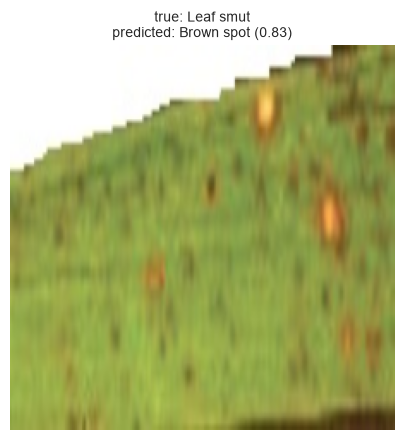

In [39]:
wrong = np.where(FINAL["y_pred"] != yte)[0]
print(f"{len(wrong)} of {len(yte)} test images misclassified")
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(5 * len(wrong), 4.5)); axes = np.atleast_1d(axes)
    for a, i in zip(axes, wrong):
        a.imshow(Xte[i].astype("uint8")); a.axis("off")
        a.set_title(f"true: {CLASSES[yte[i]]}\npredicted: {CLASSES[FINAL['y_pred'][i]]} ({FINAL['y_prob'][i].max():.2f})", fontsize=10)
    plt.tight_layout(); plt.show()

In [46]:
def row(label, r):
    cv = cv_tbl.set_index("model").loc[label]
    return dict(model=label, cv_pooled=cv.pooled_acc, train_acc=r["train_acc"], test_acc=r["test_acc"],
                test_F1=r["test_f1"], params_M=r["params_M"], train_time_s=r["train_time_s"])
final_tbl = pd.DataFrame([
    row("ResNet50 (fine-tuned)", ft_results["ResNet50"]),
    row("MobileNetV2 (fine-tuned)", ft_results["MobileNetV2"]),
    row("MobileNetV2 (frozen)", results["MobileNetV2"]),
    row("EfficientNetB0 (fine-tuned)", ft_results["EfficientNetB0"])])
final_tbl["gap (train-test)"] = final_tbl.train_acc - final_tbl.test_acc
display(final_tbl.round(3))

,model,cv_pooled,train_acc,test_acc,test_F1,params_M,train_time_s,gap (train-test)
0,ResNet50 (fine-tuned),0.911,1.0,0.833,0.831,23.594,185.971,0.167
1,MobileNetV2 (fine-tuned),0.891,1.0,0.944,0.944,2.262,73.376,0.056
2,MobileNetV2 (frozen),0.861,1.0,0.889,0.892,2.262,45.086,0.111
3,EfficientNetB0 (fine-tuned),0.861,1.0,0.833,0.833,4.053,103.936,0.167


### Summary of techniques analysed (Task 3)

| Technique | How tested | Result | Conclusion |
|---|---|---|---|
| Data augmentation (flip, rotation, zoom, shift, brightness, contrast, combined) | 8 settings, frozen MobileNetV2; 3 seeds on validation, then 5-fold CV on 101 images | CV accuracy 0.831 to 0.870 (none: 0.860) | No measurable benefit; differences within noise. Zoom used. |
| Transfer learning vs training from scratch | CustomCNN vs 5 pretrained models | CustomCNN validation 0.333 (chance); pretrained 0.83 to 1.00 | Essential with 83 training images |
| Fine-tuning vs frozen backbone | Last 30 layers unfrozen, learning rate 1e-5; test set and 5-fold CV | MobileNetV2 CV 0.861 to 0.891; test 0.889 to 0.944 | Small gain (1 to 3 images), consistent but within noise |
| Regularisation (dropout, EarlyStopping, ReduceLROnPlateau) | Used in all models | Not tested separately | Not isolated |


## 8. Model recommendation for production

**Recommended model: MobileNetV2 (ImageNet-pretrained, last 30 layers fine-tuned), trained with zoom augmentation.**

| Model | CV accuracy (101 images) | Test (18 images) | Parameters | Training time |
|---|---|---|---|---|
| ResNet50, fine-tuned | 0.911 | 0.833 | 23.6 M | about 3 min (single run), 16 min for 5-fold CV |
| **MobileNetV2, fine-tuned** | **0.891** | **0.944** | **2.3 M** | **about 73 s (single run), 5.5 min for 5-fold CV** |
| MobileNetV2, frozen | 0.861 | 0.889 | 2.3 M | about 45 s |
| EfficientNetB0, fine-tuned | 0.861 | 0.833 | 4.1 M | about 104 s |

**Reasons:**
1. Accuracy: about 89% in cross-validation, 94% on the test set. ResNet50 scored 2 images higher in cross-validation (92 vs 90 of 101), which is within noise.
2. Size and speed: MobileNetV2 has about one tenth of the parameters of ResNet50 and is designed for phones and low-power devices, which suits use in the field.
3. Generalisation: all four models reach 100% training accuracy, so the train-test gap shows overfitting. It is smallest for fine-tuned MobileNetV2 (0.056, one test image), against 0.167 for ResNet50 and EfficientNetB0 and 0.111 for frozen MobileNetV2.
4. Trained from scratch, a small CNN failed to learn (validation accuracy 0.33, chance level), so transfer learning is essential.

**Limitations before deployment:**
- Only 119 images from three diseases. Accuracy figures are imprecise (the test set has 18 images).
- The model confuses Brown spot and Leaf smut most (8 of 11 cross-validation errors), so uncertain predictions should be flagged for human review.
- Images come from one source; performance on new field photos (other cameras, lighting, backgrounds) is untested. A shortcut through image size or background cannot be ruled out.
- Recommended next steps: collect more varied images, evaluate on an independent set of new photos, and check with Grad-CAM that the model looks at the lesions.

In [40]:
i = te_idx[wrong[0]]
print("File          :", df.loc[i, "path"])
print("Original size :", df.loc[i, "width"], "x", df.loc[i, "height"], "pixels")

File          : data\images\Leaf smut\DSC_0502.jpg
Original size : 301 x 71 pixels


### Error analysis

The single test error was a Leaf smut image (DSC_0502.jpg) predicted as Brown spot with 83% confidence. The original image is only 301 x 71 pixels; resizing it to 224 x 224 compressed it horizontally to about 74% and stretched it vertically about 3.2 times, which explains the blocky, blurry appearance. Few distinguishing features survive, and the visible orange-brown spots resemble Brown spot lesions. This matches the cross-validation result, where 8 of the 11 errors were Brown spot / Leaf smut confusions. Likely causes: very low resolution with strong distortion from resizing, small lesions, and visual similarity between the two diseases. Possible improvements: higher-resolution, more consistent photos; more training images of these two classes; padding or cropping instead of squashing images. The model's confidence (0.83) was high for a wrong prediction, so confidence alone should not be trusted; low-resolution inputs should be flagged for review.

## 9. Report on challenges faced

| # | Challenge | What I observed | Technique used | Reasoning |
|---|---|---|---|---|
| 1 | **Very small dataset** | 119 images; 83 for training. A CNN trained from scratch stayed at chance (validation accuracy 0.33) | Transfer learning from ImageNet, dropout, EarlyStopping, ReduceLROnPlateau | Pretrained features need far fewer images; the regularisers limit memorisation |
| 2 | **Dataset packaging** | The download contained three more zip files (one per class), not image folders | Extracted both levels in code | Makes the preparation reproducible |
| 3 | **Brief did not match the data** | The brief says 120 images and "leaf blast"; the data has 119 images (Leaf smut has 39) and the class is "Leaf smut" | Used the actual folder names and counts | The model can only learn the labels that exist in the data |
| 4 | **Very inconsistent image sizes** | 34 unique sizes; 85 images are 3081 x 897, the other 34 are as small as 250 x 71 | Resized everything to 224 x 224 | Pretrained models need one fixed square input; plain resizing distorts the wide images and shrinks small lesions |
| 5 | **Possible shortcut through image size** | Small images occur only in Brown spot and Leaf smut; a size-only rule would score about 50% | Checked the size-class relationship; verified the model scores well above 50% | Prevents mistaking image format for disease recognition |
| 6 | **Different input scaling per pretrained network** | Each architecture expects its own preprocessing | Applied each model's own `preprocess_input` inside the model | The wrong scaling silently lowers accuracy |
| 7 | **Leakage risk** | Augmented copies could end up in test data | Split first (stratified 70/15/15), augmented only inside the training pipeline | Test results stay honest |
| 8 | **Tiny validation and test sets (18 images each)** | Validation accuracy of 94 to 100% was optimistic; cross-validation gave about 86 to 91% | Several seeds, stratified 5-fold cross-validation on 101 images, decisions made on CV not on one split | One image is 5.6 points, so one split is mostly noise |
| 9 | **Augmentation showed no clear benefit** | CV accuracy 0.831 to 0.870 across settings, differences within noise | Reported honestly; used zoom because it scored highest and addresses framing variation | Differences smaller than fold-to-fold variation cannot be claimed as real |
| 10 | **Overfitting of larger models** | Train accuracy 1.00 vs test 0.78 to 0.89 for pretrained models | Frozen backbone first, then fine-tuning of only the last 30 layers at a low learning rate with BatchNorm frozen; compared train-test gaps | Large updates on few images destroy pretrained features |
| 11 | **Similar-looking diseases** | 8 of 11 cross-validation errors were Brown spot / Leaf smut | Error analysis of misclassified images; recommended more data and review of uncertain cases | Both diseases appear as small dark marks on green leaves |
| 12 | **No GPU (native Windows)** | VGG16 took 647 s for 20 epochs and was still improving | Measured time per model, fine-tuned only the top three, chose the smaller model when accuracy was tied | Kept all experiments feasible on a CPU |
| 13 | **Environment setup problems** | Conda install failed and pip stalled | See the appendix | |

## Appendix: environment setup issues and fixes

| Issue | Cause | Fix |
|---|---|---|
| `conda create` failed ("Cannot link a source that does not exist") and left an empty environment folder | Corrupted conda package cache;| Deleted the empty folder, ran `conda clean --all`, recreated the environment |
| `pip install` of all libraries at once ran endlessly (backtracking) with interrupted downloads | Too many packages to resolve together on a slow connection | Upgraded pip; installed TensorFlow alone, then the rest, with `--default-timeout` and `--retries` |
| `jupyter` not recognised in the terminal | Jupyter was not installed in the `riceleaf` environment | Installed `notebook` and `ipykernel` inside `riceleaf` |
| Dataset had no class folders after extraction | The zip contained one zip per class | Extracted the second level in code |

## 10. Conclusion

The dataset has 119 images of three rice leaf diseases (Bacterial leaf blight 40, Brown spot 40, Leaf smut 39), balanced but very small, with highly inconsistent image sizes. Pretrained models were essential: a CNN trained from scratch failed to learn, while ImageNet-pretrained networks reached about 86 to 91% in cross-validation. Data augmentation gave no measurable benefit in this setup. Fine-tuned MobileNetV2 was selected because it was statistically indistinguishable from the larger ResNet50 but about ten times smaller; it reached 0.891 accuracy in cross-validation (90 of 101 images) and 0.944 on the test set (17 of 18). The main weakness is separating Brown spot from Leaf smut. Results are limited by the dataset size, a single image source and untested field conditions. Next steps: collect more varied, higher-resolution images, test on independent photos, crop around lesions, and use Grad-CAM to confirm the model attends to the lesions.